# Data Loading

In [4]:
%%time

#### NOte: rename weight column to weight_algo column

import kpex_dev
import data_splits
import warnings
import pandas as pd
import numpy as np
from openpyxl import Workbook

# create once, pass around multiple times for writing metrics
wb = Workbook()

warnings.filterwarnings('ignore')

timeout_replacement = 1800  # max timeout replacement
file_path = r"..\input_data\results-filtered-dataset.txt"


feature_cols = data_splits.feature_cols
algorithms = data_splits.algorithms


CPU times: total: 0 ns
Wall time: 0 ns


In [5]:
# Loading and preprocessing data
cat_df= kpex_dev.load_excel_data(file_path, timeout_replacement)
kpex_dev.process_kcore_list_to_statistics(cat_df)

# Selecting weight scheme
epsilon = 0.001 # need to set !!!
scheme = kpex_dev.W_TIME_MIN_X_W_LOG_TIME_RATIO # Change this and analyse!!

# Assigning weights
kpex_dev.assign_weights(cat_df, scheme, epsilon)

# kpex_dev.export_sorted(cat_df)

# Data reformatting
cat_df = kpex_dev.post_process_data(cat_df)
cat_df

,dataset,k_value,n,m,d_avg,d_max,core_max,core_min,shell_num,shell_avgSize,...,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P,kPEX,kPEX-S,kPEX-R,kPEX-P
0,12month1,20,52328,1585220,30.294,9214,57,19,39,16785.102564,...,1800.000000,1800.000000,1800.000000,131.0240,121.2490,117.7020,116.0158,124.7390,125.8084,126.1804
1,130bit,8,584,6059,10.375,322,12,8,5,564.400000,...,3.196156,1.179364,0.653300,2.3643,0.7011,0.8350,1.4934,0.4922,0.9836,1.7554
2,130bit,9,584,6059,10.375,322,12,8,5,564.400000,...,39.330518,2.159862,2.485482,34.7253,3.2734,3.0159,38.6679,4.9357,22.5385,47.5120
3,130bit,10,583,6051,10.379,321,12,9,4,559.500000,...,9.695851,7.271823,1.946958,9.4931,3.0985,2.4184,10.8117,2.0049,10.4852,12.4310
4,144,4,144319,1072349,7.430,26,9,7,3,140266.333333,...,0.588537,0.539013,0.755349,1.0679,1.0694,0.9626,0.9761,1.0700,1.0626,1.1065
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4351,zhishi-zhwiki-internallink,7,4666,248342,53.224,2014,99,19,81,2293.913580,...,2.349277,2.272406,2.238443,1.8562,2.2227,2.2188,1.8133,1.8370,2.2205,2.1942
4352,zhishi-zhwiki-internallink,8,6109,313420,51.305,2421,101,19,83,2731.265060,...,3.851166,3.097895,2.829056,2.8021,2.4912,2.5297,2.8437,2.3888,2.3317,2.8890
4353,zhishi-zhwiki-internallink,9,5981,309664,51.775,2406,101,20,82,2688.695122,...,6.984801,2.970734,2.855774,2.4142,2.4424,2.7942,2.4207,2.5012,2.5222,2.9436
4354,zhishi-zhwiki-internallink,10,4419,244006,55.217,1989,99,22,78,2204.871795,...,13.381666,7.638818,3.442978,1.8692,1.8513,1.6981,1.7289,1.7092,1.7741,1.7088


## Scheme 2 - Hierarchial model


<!-- - Hierarchial model -->
Algorithms are divided into groups and sub-groups, each having their own classifier.
At each level of the hierarchy, we apply a confidence threshold τ to prevent low-confidence predictions from propagating downstream.

![image.png](attachment:image.png)

Tie Breaking and Data Splitting

In [6]:
ALT_RB_ALGOS = ["UMKP+-S", "UMKP+-R", "UMKP+-P"]
NO_ALT_RB_ALGOS = ["UMKP-S", "UMKP-R", "UMKP-P"]
SPARSE_ALGOS = ALT_RB_ALGOS + NO_ALT_RB_ALGOS
DENSE_ALGOS = ["kPEX", "kPEX-S", "kPEX-R", "kPEX-P"]

ALL_ALGOS = ALT_RB_ALGOS + NO_ALT_RB_ALGOS + DENSE_ALGOS


Step 1: Fastest leaf algorithm per row

In [7]:
def get_fastest_algorithm(row, algorithms):
    times = np.array([row[a] for a in algorithms], dtype=float)
    return algorithms[np.argmin(times)]

cat_df["y_algo"] = cat_df.apply(
    lambda r: get_fastest_algorithm(r, ALL_ALGOS),
    axis=1
)


Step 2: Create y_group

In [8]:
def map_group(algo):
    if algo in DENSE_ALGOS:
        return "Dense"
    return "Sparse"

cat_df["y_group"] = cat_df["y_algo"].apply(map_group)


Step 3: Create y_sparse_subgroup

In [9]:
def map_sparse_subgroup(algo):
    if algo in ALT_RB_ALGOS:
        return "AltRB"
    if algo in NO_ALT_RB_ALGOS:
        return "No-AltRB"
    return None

cat_df["y_sparse_subgroup"] = cat_df["y_algo"].apply(map_sparse_subgroup)


Step 4: Deriving Weights for Each Classifier

In [10]:
# Classifier 1 (Sparse vs Dense)
# weight should reflect relative difficulty between Sparse and Dense.
def compute_group_weight(row, epsilon=1e-3):
    sparse_vals = np.array([row[a] for a in SPARSE_ALGOS], dtype=float)
    dense_vals = np.array([row[a] for a in DENSE_ALGOS], dtype=float)

    sparse_best = sparse_vals.min()
    dense_best = dense_vals.min()

    vals = np.array([sparse_best, dense_best])

    min_val = vals.min()
    max_val = vals.max()

    if min_val == 0:
        ratio = max_val / epsilon
    else:
        ratio = max_val / min_val

    return np.log(1 + min_val) + np.log(ratio)

cat_df["weight_group"] = cat_df.apply(compute_group_weight, axis=1)


# Classifier 2 (Sparse: AltRB vs No-AltRB); distinguishes within sparse category
# weight should reflect relative difficulty between AltRB and No-AltRB.
# We recompute using only sparse algorithms

def compute_sparse_weight(row, epsilon=1e-3):
    vals = np.array([row[a] for a in SPARSE_ALGOS], dtype=float)
    min_val = vals.min()
    max_val = vals.max()

    if min_val == 0:
        ratio = max_val / epsilon
    else:
        ratio = max_val / min_val

    return np.log(1 + min_val) + np.log(ratio)

cat_df["weight_sparse_subgroup"] = cat_df.apply(compute_sparse_weight, axis=1)


# Classifier 3 (AltRB leaf) Only AltRB rows matter
cat_df["weight_altRB"] = np.where(
    cat_df["y_sparse_subgroup"] == "AltRB",
    cat_df["weight"],
    0
)

# Classifier 4 (No-AltRB leaf)
cat_df["weight_noAltRB"] = np.where(
    cat_df["y_sparse_subgroup"] == "No-AltRB",
    cat_df["weight"],
    0
)


# Classifier 5 (Dense leaf)
cat_df["weight_dense"] = cat_df["weight"]



In [11]:
cat_df

,dataset,k_value,n,m,d_avg,d_max,core_max,core_min,shell_num,shell_avgSize,...,kPEX-R,kPEX-P,y_algo,y_group,y_sparse_subgroup,weight_group,weight_sparse_subgroup,weight_altRB,weight_noAltRB,weight_dense
0,12month1,20,52328,1585220,30.294,9214,57,19,39,16785.102564,...,125.8084,126.1804,kPEX,Dense,None,4.776739,7.504002,0.000000,0.000000,318.093925
1,130bit,8,584,6059,10.375,322,12,8,5,564.400000,...,0.9836,1.7554,kPEX-S,Dense,None,0.683403,2.090441,0.000000,0.000000,0.920817
2,130bit,9,584,6059,10.375,322,12,8,5,564.400000,...,22.5385,47.5120,UMKP-R,Sparse,No-AltRB,1.976979,4.052485,0.000000,6.675999,6.675999
3,130bit,10,583,6051,10.379,321,12,9,4,559.500000,...,10.4852,12.4310,UMKP-P,Sparse,No-AltRB,1.110099,2.686203,0.000000,3.609514,3.609514
4,144,4,144319,1072349,7.430,26,9,7,3,140266.333333,...,1.0626,1.1065,UMKP-R,Sparse,No-AltRB,1.024967,1.116255,0.000000,0.387668,0.387668
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4351,zhishi-zhwiki-internallink,7,4666,248342,53.224,2014,99,19,81,2293.913580,...,2.2205,2.1942,kPEX,Dense,None,1.057741,1.285068,0.000000,0.000000,0.469571
4352,zhishi-zhwiki-internallink,8,6109,313420,51.305,2421,101,19,83,2731.265060,...,2.3317,2.8890,kPEX-R,Dense,None,1.269650,1.685857,0.000000,0.000000,1.169997
4353,zhishi-zhwiki-internallink,9,5981,309664,51.775,2406,101,20,82,2688.695122,...,2.5222,2.9436,UMKP+-S,Sparse,AltRB,1.230632,2.290312,2.564770,0.000000,2.564770
4354,zhishi-zhwiki-internallink,10,4419,244006,55.217,1989,99,22,78,2204.871795,...,1.7741,1.7088,UMKP+-P,Sparse,AltRB,0.998829,3.056923,3.505516,0.000000,3.505516


### Classifiers

In [32]:
import numpy as np


class HierarchicalClassifier5:
    def __init__(
        self,
        group_clf,
        sparse_subgroup_clf,
        altRB_clf,
        noAltRB_clf,
        dense_clf,
        le_group,
        le_sparse,
        le_algo,
        tau_group=0.0,
        tau_sparse=0.0,
        tau_algo=0.0,
        fallback_label=None
    ):

        self.group_clf = group_clf
        self.sparse_subgroup_clf = sparse_subgroup_clf
        self.altRB_clf = altRB_clf
        self.noAltRB_clf = noAltRB_clf
        self.dense_clf = dense_clf

        self.le_group = le_group
        self.le_sparse = le_sparse
        self.le_algo = le_algo

        self.tau_group = tau_group
        self.tau_sparse = tau_sparse
        self.tau_algo = tau_algo

        self.fallback_label = fallback_label

        self.classes_ = self.le_algo.classes_

        # Will store local → global mappings
        self.alt_map = None
        self.noalt_map = None
        self.dense_map = None

    # --------------------------------------------------
    def _reindex_labels(self, y_subset):
        """
        Reindex arbitrary label integers into 0..k-1.
        Returns:
            y_local (reindexed),
            forward_map (global → local),
            inverse_map (local → global)
        """
        unique = np.unique(y_subset)
        forward_map = {g: i for i, g in enumerate(unique)}
        inverse_map = {i: g for g, i in forward_map.items()}
        y_local = np.array([forward_map[g] for g in y_subset])
        return y_local, forward_map, inverse_map

    # --------------------------------------------------
    def fit(
        self,
        X,
        y_group_enc,
        y_sparse_enc,
        y_algo_enc,
        weight_group=None,
        weight_sparse=None,
        weight_altRB=None,
        weight_noAltRB=None,
        weight_dense=None,
    ):

        X = np.asarray(X)
        y_group_enc = np.asarray(y_group_enc)
        y_sparse_enc = np.asarray(y_sparse_enc)
        y_algo_enc = np.asarray(y_algo_enc)

        # ---------------- Stage 1 ----------------
        self.group_clf.fit(X, y_group_enc, sample_weight=weight_group)

        # ---------------- Stage 2 ----------------
        sparse_label = self.le_group.transform(["Sparse"])[0]
        sparse_idx = (y_group_enc == sparse_label)

        self.sparse_subgroup_clf.fit(
            X[sparse_idx],
            y_sparse_enc[sparse_idx],
            sample_weight=None if weight_sparse is None else weight_sparse[sparse_idx]
        )

        # ---------------- Stage 3 (AltRB) ----------------
        alt_label = self.le_sparse.transform(["AltRB"])[0]
        alt_idx = (y_sparse_enc == alt_label)

        y_local, _, inverse_map = self._reindex_labels(y_algo_enc[alt_idx])
        self.alt_map = inverse_map

        self.altRB_clf.fit(
            X[alt_idx],
            y_local,
            sample_weight=None if weight_altRB is None else weight_altRB[alt_idx]
        )

        # ---------------- Stage 4 (No-AltRB) ----------------
        no_label = self.le_sparse.transform(["No-AltRB"])[0]
        no_idx = (y_sparse_enc == no_label)

        y_local, _, inverse_map = self._reindex_labels(y_algo_enc[no_idx])
        self.noalt_map = inverse_map

        self.noAltRB_clf.fit(
            X[no_idx],
            y_local,
            sample_weight=None if weight_noAltRB is None else weight_noAltRB[no_idx]
        )

        # ---------------- Stage 5 (Dense) ----------------
        dense_label = self.le_group.transform(["Dense"])[0]
        dense_idx = (y_group_enc == dense_label)

        y_local, _, inverse_map = self._reindex_labels(y_algo_enc[dense_idx])
        self.dense_map = inverse_map

        self.dense_clf.fit(
            X[dense_idx],
            y_local,
            sample_weight=None if weight_dense is None else weight_dense[dense_idx]
        )

        return self

    # --------------------------------------------------
    def predict(self, X):
        proba = self.predict_proba(X)
        pred_enc = np.argmax(proba, axis=1)
        return self.le_algo.inverse_transform(pred_enc)

    # --------------------------------------------------
    def predict_proba(self, X):

        X = np.asarray(X)
        n_samples = X.shape[0]
        n_classes = len(self.le_algo.classes_)

        proba = np.zeros((n_samples, n_classes))

        p_group = self.group_clf.predict_proba(X)

        idx_sparse = self.le_group.transform(["Sparse"])[0]
        idx_dense = self.le_group.transform(["Dense"])[0]

        idx_alt = self.le_sparse.transform(["AltRB"])[0]
        idx_no = self.le_sparse.transform(["No-AltRB"])[0]

        for i in range(n_samples):

            p_sparse = p_group[i, idx_sparse]
            p_dense = p_group[i, idx_dense]

            # ---------- Dense branch ----------
            p_dense_leaf = self.dense_clf.predict_proba(
                X[i].reshape(1, -1)
            )[0]

            for local_class, p_leaf in enumerate(p_dense_leaf):
                global_class = self.dense_map[local_class]
                proba[i, global_class] += p_dense * p_leaf

            # ---------- Sparse branch ----------
            p_sparse_sub = self.sparse_subgroup_clf.predict_proba(
                X[i].reshape(1, -1)
            )[0]

            p_alt = p_sparse * p_sparse_sub[idx_alt]
            p_no = p_sparse * p_sparse_sub[idx_no]

            # ---- AltRB leaf ----
            p_alt_leaf = self.altRB_clf.predict_proba(
                X[i].reshape(1, -1)
            )[0]

            for local_class, p_leaf in enumerate(p_alt_leaf):
                global_class = self.alt_map[local_class]
                proba[i, global_class] += p_alt * p_leaf

            # ---- No-AltRB leaf ----
            p_no_leaf = self.noAltRB_clf.predict_proba(
                X[i].reshape(1, -1)
            )[0]

            for local_class, p_leaf in enumerate(p_no_leaf):
                global_class = self.noalt_map[local_class]
                proba[i, global_class] += p_no * p_leaf

        return proba

In [13]:
from xgboost import XGBClassifier

# ----- Stage 1: Sparse vs Dense (Binary) -----
group_clf = XGBClassifier(
    objective="binary:logistic",
    n_estimators=400,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    use_label_encoder=False,
    random_state=42
)


# ----- Stage 2: Sparse → AltRB vs No-AltRB (Binary) -----
sparse_subgroup_clf = XGBClassifier(
    objective="binary:logistic",
    n_estimators=400,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    use_label_encoder=False,
    random_state=42
)


# ----- Stage 3: AltRB algorithms (3-class) -----
altRB_clf = XGBClassifier(
    objective="multi:softprob",
    num_class=3,     # UMKP+-S, UMKP+-R, UMKP+-P
    n_estimators=400,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    use_label_encoder=False,
    random_state=42
)


# ----- Stage 4: No-AltRB algorithms (3-class) -----
noAltRB_clf = XGBClassifier(
    objective="multi:softprob",
    num_class=3,     # UMKP-S, UMKP-R, UMKP-P
    n_estimators=400,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    use_label_encoder=False,
    random_state=42
)


# ----- Stage 5: Dense algorithms (4-class) -----
dense_clf = XGBClassifier(
    objective="multi:softprob",
    num_class=4,     # kPEX, kPEX-S, kPEX-R, kPEX-P
    n_estimators=400,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    use_label_encoder=False,
    random_state=42
)

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)


def evaluate_hierarchical_stages(results_df, hclf5, X_full, algorithms):

    summary_rows = []
    per_class_reports = {}

    def clean_labels(y_true, y_pred):
        mask = pd.notnull(y_true) & pd.notnull(y_pred)
        return y_true[mask], y_pred[mask]

    def evaluate_stage(stage_name, y_true, y_pred, labels, enforce_order=False):

        y_true, y_pred = clean_labels(
            np.array(y_true),
            np.array(y_pred)
        )

        if enforce_order:
            label_order = labels
        else:
            label_order = sorted(list(set(y_true) | set(y_pred)))

        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
        rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

        summary_rows.append({
            "Stage": stage_name,
            "Samples": len(y_true),
            "Accuracy": acc,
            "Avg Precision": prec,
            "Avg Recall": rec,
            "Avg F1": f1
        })

        report = classification_report(
            y_true,
            y_pred,
            labels=label_order,
            output_dict=True,
            zero_division=0
        )

        per_class_reports[stage_name] = pd.DataFrame(report).T

        cm = confusion_matrix(y_true, y_pred, labels=label_order)

        disp = ConfusionMatrixDisplay(
            cm,
            display_labels=label_order
        )

        fig, ax = plt.subplots(figsize=(5, 5))
        disp.plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(stage_name)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    # =====================================================
    # Stage 1 (Sparse vs Dense)
    # =====================================================
    y_true = results_df['y_group'].values
    y_pred_enc = hclf5.group_clf.predict(X_full)
    y_pred = hclf5.le_group.inverse_transform(y_pred_enc)

    evaluate_stage(
        "Stage 1 (Sparse vs Dense)",
        y_true,
        y_pred,
        labels=["Sparse", "Dense"],   # FORCE ORDER
        enforce_order=True
    )

    # =====================================================
    # Stage 2 (AltRB vs No-AltRB)
    # =====================================================
    mask = results_df['y_group'] == "Sparse"
    if mask.sum() > 0:

        y_true = results_df.loc[mask, 'y_sparse_subgroup'].values
        y_pred_enc = hclf5.sparse_subgroup_clf.predict(X_full[mask])
        y_pred = hclf5.le_sparse.inverse_transform(y_pred_enc)

        evaluate_stage(
            "Stage 2 (AltRB vs No-AltRB)",
            y_true,
            y_pred,
            labels=["AltRB", "No-AltRB"],
            enforce_order=True
        )

    # =====================================================
    # Stage 3 (AltRB leaf)
    # =====================================================
    mask = results_df['y_sparse_subgroup'] == "AltRB"
    if mask.sum() > 0:

        y_true = results_df.loc[mask, 'y_algo'].values
        y_pred_local = hclf5.altRB_clf.predict(X_full[mask])
        y_pred_global_enc = np.array(
            [hclf5.alt_map[i] for i in y_pred_local]
        )
        y_pred = hclf5.le_algo.inverse_transform(y_pred_global_enc)

        evaluate_stage(
            "Stage 3 (AltRB leaf)",
            y_true,
            y_pred,
            labels=sorted(set(y_true)),
            enforce_order=False
        )

    # =====================================================
    # Stage 4 (No-AltRB leaf)
    # =====================================================
    mask = results_df['y_sparse_subgroup'] == "No-AltRB"
    if mask.sum() > 0:

        y_true = results_df.loc[mask, 'y_algo'].values
        y_pred_local = hclf5.noAltRB_clf.predict(X_full[mask])
        y_pred_global_enc = np.array(
            [hclf5.noalt_map[i] for i in y_pred_local]
        )
        y_pred = hclf5.le_algo.inverse_transform(y_pred_global_enc)

        evaluate_stage(
            "Stage 4 (No-AltRB leaf)",
            y_true,
            y_pred,
            labels=sorted(set(y_true)),
            enforce_order=False
        )

    # =====================================================
    # Stage 5 (Dense leaf)
    # =====================================================
    mask = results_df['y_group'] == "Dense"
    if mask.sum() > 0:

        y_true = results_df.loc[mask, 'y_algo'].values
        y_pred_local = hclf5.dense_clf.predict(X_full[mask])
        y_pred_global_enc = np.array(
            [hclf5.dense_map[i] for i in y_pred_local]
        )
        y_pred = hclf5.le_algo.inverse_transform(y_pred_global_enc)

        evaluate_stage(
            "Stage 5 (Dense leaf)",
            y_true,
            y_pred,
            labels=sorted(set(y_true)),
            enforce_order=False
        )

    # =====================================================
    # Final End-to-End
    # =====================================================
    y_true = results_df['y_algo'].values
    y_pred = hclf5.predict(X_full)

    evaluate_stage(
        "Final (End-to-End)",
        y_true,
        y_pred,
        labels=algorithms,
        enforce_order=True
    )

    summary_df = pd.DataFrame(summary_rows)

    print("\n==============================")
    print("Stage-wise Summary Metrics")
    print("==============================\n")
    print(summary_df)

    return summary_df, per_class_reports

In [38]:
import os
import numpy as np
import pandas as pd
from metrics import evaluate_algorithm_performance, evaluate_time_metrics, evaluate_with_tolerance, evaluate_time_metrics_with_tol 
def get_fastest_algorithms(row): 
    algorithms = data_splits.algorithms 
    times = [row[alg] for alg in algorithms] 
    min_time = min(times) 
    return [alg for alg in algorithms if row[alg] == min_time]

def run_full_evaluation_hier5(
    cat_df: pd.DataFrame,
    clf,
    features: list,
    algorithms: list,
    le=None,
    drop_indices: list = None,
    epsilon: float = 1e-3,
    tol: float = 0.0,
    save_files: bool = False,
    output_dir: str = './',
    file_suffix: str = "hierarchical_eval",
    kcore_list: bool = False,
    for_nn: bool = False
):

    results_df = cat_df.copy()

    # --------------------------------------------------
    # 1️⃣ True fastest algorithms
    # --------------------------------------------------
    results_df['fastest_algorithms'] = results_df.apply(
        get_fastest_algorithms, axis=1
    )

    # --------------------------------------------------
    # 2️⃣ Prepare features
    # --------------------------------------------------
    if kcore_list:
        X_full = results_df[features + ['kcore_list']].values
    elif for_nn:
        X_full = results_df[features + ['fastest_time']].values
    else:
        X_full = results_df[features].values

    # --------------------------------------------------
    # 3️⃣ Final Predictions
    # --------------------------------------------------
    print("Predicting final outputs...")
    y_pred = clf.predict(X_full)
    results_df['predicted'] = y_pred

    results_df['correct'] = results_df.apply(
        lambda row: row['predicted'] in row['fastest_algorithms'],
        axis=1
    )

    # --------------------------------------------------
    # 4️⃣ Final Leaf Probabilities
    # --------------------------------------------------
    proba_cols = []
    if hasattr(clf, "predict_proba"):
        print("Adding hierarchical leaf probabilities...")
        probas = clf.predict_proba(X_full)

        for i, cls in enumerate(clf.classes_):
            col = f"prob_{cls}"
            results_df[col] = probas[:, i]
            proba_cols.append(col)

    # --------------------------------------------------
    # 5️⃣ Stage-wise Probabilities
    # --------------------------------------------------
    print("Adding hierarchical stage probabilities...")

    # Stage 1
    p_group = clf.group_clf.predict_proba(X_full)
    for i, cls in enumerate(clf.group_clf.classes_):
        results_df[f"prob_stage1_{cls}"] = p_group[:, i]

    # Stage 2 (Sparse only)
    sparse_mask = results_df['y_group'] == "Sparse"
    if sparse_mask.any():
        X_sparse = X_full[sparse_mask]
        p_sparse = clf.sparse_subgroup_clf.predict_proba(X_sparse)
        for i, cls in enumerate(clf.sparse_subgroup_clf.classes_):
            results_df.loc[sparse_mask, f"prob_stage2_{cls}"] = p_sparse[:, i]

    # Stage 3 (AltRB)
    alt_mask = results_df['y_sparse_subgroup'] == "AltRB"
    if alt_mask.any():
        X_alt = X_full[alt_mask]
        p_alt = clf.altRB_clf.predict_proba(X_alt)
        for i, cls in enumerate(clf.altRB_clf.classes_):
            results_df.loc[alt_mask, f"prob_stage3_{cls}"] = p_alt[:, i]

    # Stage 4 (No-AltRB)
    noalt_mask = results_df['y_sparse_subgroup'] == "No-AltRB"
    if noalt_mask.any():
        X_noalt = X_full[noalt_mask]
        p_noalt = clf.noAltRB_clf.predict_proba(X_noalt)
        for i, cls in enumerate(clf.noAltRB_clf.classes_):
            results_df.loc[noalt_mask, f"prob_stage4_{cls}"] = p_noalt[:, i]

    # Stage 5 (Dense)
    dense_mask = results_df['y_group'] == "Dense"
    if dense_mask.any():
        X_dense = X_full[dense_mask]
        p_dense = clf.dense_clf.predict_proba(X_dense)
        for i, cls in enumerate(clf.dense_clf.classes_):
            results_df.loc[dense_mask, f"prob_stage5_{cls}"] = p_dense[:, i]

    # --------------------------------------------------
    # 6️⃣ Classification Metrics
    # --------------------------------------------------
    print("\nClassification performance:")
    if tol > 0:
        out_dict_1 = evaluate_with_tolerance(results_df, algorithms, tol=tol)
    else:
        out_dict_1 = evaluate_algorithm_performance(results_df, algorithms)

    # --------------------------------------------------
    # 7️⃣ Time Metrics
    # --------------------------------------------------
    df_time = results_df
    if drop_indices:
        df_time = df_time.drop(index=drop_indices, errors='ignore')

    if tol > 0:
        out_dict_2 = evaluate_time_metrics_with_tol(
            df_time, algorithms, tol=tol, epsilon=epsilon
        )
    else:
        out_dict_2 = evaluate_time_metrics(
            df_time, algorithms, epsilon=epsilon
        )

    # --------------------------------------------------
    # Create Top-3 Most Likely Predictions Column
    # --------------------------------------------------
    def get_top3(row):
        probs = {alg: row[f"prob_{alg}"] for alg in algorithms}
        top3 = sorted(probs.items(), key=lambda x: x[1], reverse=True)[:3]
        return top3
        # return ", ".join([alg for alg, _ in top3])

    results_df["top3_predicted"] = results_df.apply(get_top3, axis=1)
    
    # --------------------------------------------------
    # 8️⃣ Wrong Predictions
    # --------------------------------------------------
    wrong_df = results_df[~results_df['correct']].copy()

    # --------------------------------------------------
    # 9️⃣ Save Files
    # --------------------------------------------------
    if save_files:
        os.makedirs(output_dir, exist_ok=True)

        # Save full predictions
        full_path = os.path.join(
            output_dir,
            f"all_predictions_{file_suffix}.csv"
        )

        save_cols = (
            ['dataset', 'k_value', 'fastest_algorithms',
             'predicted', 'correct', 'top3_predicted']
            + algorithms
            + proba_cols
            + [c for c in results_df.columns if c.startswith("prob_stage")]
        )

        results_df[save_cols].to_csv(full_path, index=False)
        print(f"\nSaved full results to: {full_path}")

        # Save wrong predictions
        wrong_path = os.path.join(
            output_dir,
            f"wrong_predictions_{file_suffix}.csv"
        )

        wrong_df[save_cols].to_csv(wrong_path, index=False)
        print(f"Saved wrong predictions to: {wrong_path}")

    return out_dict_1, out_dict_2, results_df, wrong_df


import os
from openpyxl import Workbook, load_workbook

def write_metrics_to_excel_file(
    cls_metrics: dict,
    time_metrics: dict,
    filepath: str,
    sheet_name: str = "Metrics"
):
    """
    Append a new sheet of metrics to an Excel file (or create it if missing).
    Compatible with hierarchical metrics output.
    """

    # -----------------------------
    # 1) Open or create workbook
    # -----------------------------
    if os.path.exists(filepath):
        wb = load_workbook(filepath)
        if sheet_name in wb.sheetnames:
            wb.remove(wb[sheet_name])
    else:
        wb = Workbook()
        default = wb.sheetnames[0]
        if default == "Sheet":
            wb.remove(wb[default])

    ws = wb.create_sheet(title=sheet_name)

    rows = []

    # -----------------------------
    # 2) Overall Accuracy
    # -----------------------------
    if 'accuracy' in cls_metrics:
        rows.append([
            "Overall Accuracy (in %)",
            f"{cls_metrics['accuracy'] * 100:.2f}"
        ])
        rows.append([])

    # -----------------------------
    # 3) Precision
    # -----------------------------
    if 'precision_per_alg' in cls_metrics:
        rows.append(["Precision by Algorithm (in %):", ""])
        for alg, prec in cls_metrics['precision_per_alg'].items():
            rows.append([alg, f"{prec * 100:.2f}"])
        rows.append([])

    # -----------------------------
    # 4) Average Precision (AP)
    # -----------------------------
    if 'ap_per_alg' in cls_metrics:
        rows.append(["Average Precision (AP) by Algorithm (in %):", ""])
        for alg, ap in cls_metrics['ap_per_alg'].items():
            if ap is None:
                rows.append([alg, "N/A"])
            else:
                rows.append([alg, f"{ap * 100:.2f}"])
        rows.append([])

    # -----------------------------
    # 5) Recall
    # -----------------------------
    if 'recall_per_alg' in cls_metrics:
        rows.append(["Recall by Algorithm (in %):", ""])
        for alg, rec in cls_metrics['recall_per_alg'].items():
            rows.append([alg, f"{rec * 100:.2f}"])
        rows.append([])

    # -----------------------------
    # 6) Time Metrics
    # -----------------------------
    if time_metrics:
        rows.append(["Time Metrics", ""])
        if 'total_time_pred' in time_metrics:
            rows.append([
                "Total Predicted Time (seconds)",
                f"{time_metrics['total_time_pred']:.2f}"
            ])
        if 'total_time_opt' in time_metrics:
            rows.append([
                "Total Optimal Time (seconds)",
                f"{time_metrics['total_time_opt']:.2f}"
            ])
        if 'time_ratio' in time_metrics:
            rows.append([
                "Time Ratio (pred/opt)",
                f"{time_metrics['time_ratio']:.3f}"
            ])
        if 'avg_overhead_per_case' in time_metrics:
            rows.append([
                "Avg Overhead per Case (in %)",
                f"{time_metrics['avg_overhead_per_case'] * 100:.2f}"
            ])

    # -----------------------------
    # 7) Write to Sheet
    # -----------------------------
    for r in rows:
        ws.append(r)

    ws.column_dimensions['A'].width = 55
    ws.column_dimensions['B'].width = 22

    wb.save(filepath)
    wb.close()

    print(f"Metrics written to {filepath}")


import pandas as pd
import os

def save_stage_reports(report_obj, file_name, output_dir="./", to_excel=True):

    os.makedirs(output_dir, exist_ok=True)

    if to_excel:
        file_path = os.path.join(output_dir, f"{file_name}.xlsx")

        with pd.ExcelWriter(file_path, engine="openpyxl") as writer:
            if isinstance(report_obj, dict):
                for stage, df in report_obj.items():
                    sheet_name = stage[:31]  # Excel limit
                    df.to_excel(writer, sheet_name=sheet_name)
            elif isinstance(report_obj, pd.DataFrame):
                report_obj.to_excel(writer, sheet_name="Report")
            else:
                raise ValueError("report_obj must be dict or DataFrame")

        print(f"\nSaved stage report to: {file_path}")

    else:
        file_path = os.path.join(output_dir, f"{file_name}.csv")

        if isinstance(report_obj, dict):
            combined_df = pd.concat(report_obj, names=["Stage"])
            combined_df.to_csv(file_path)
        elif isinstance(report_obj, pd.DataFrame):
            report_obj.to_csv(file_path)
        else:
            raise ValueError("report_obj must be dict or DataFrame")

        print(f"\nSaved stage report to: {file_path}")



### **Balanced train-test split based on Y**

In [16]:
from sklearn.model_selection import train_test_split
import pandas as pd

def prepare_train_test_strat_Y_hier(cat_df,
                       weight_col='weight',
                       test_size=0.2,
                       random_state=42,
                       for_nn=False,
                       kcore_list=None,
                       tie_tolerance=0.00):

    if kcore_list:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize', 'kcore_list']
    elif for_nn:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize', 'fastest_time']
    else:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize']

    # No expansion anymore — labels already computed
    X = cat_df[feature_cols]

    y_algo = cat_df['y_algo']
    y_group = cat_df['y_group']
    y_sparse_subgroup = cat_df['y_sparse_subgroup']

    # Per-classifier weights
    weight_group = cat_df['weight_group']
    weight_sparse = cat_df['weight_sparse_subgroup']
    weight_altRB = cat_df['weight_altRB']
    weight_noAltRB = cat_df['weight_noAltRB']
    weight_dense = cat_df['weight_dense']

    X_train, X_test, \
    y_algo_train, y_algo_test = train_test_split(
        X, y_algo,
        test_size=test_size,
        random_state=random_state,
        stratify=y_algo
    )

    # Align splits
    idx_train = X_train.index
    idx_test = X_test.index

    return (
        X_train, X_test,
        y_algo_train, y_algo_test,

        y_group.loc[idx_train], y_group.loc[idx_test],
        y_sparse_subgroup.loc[idx_train], y_sparse_subgroup.loc[idx_test],

        weight_group.loc[idx_train], weight_group.loc[idx_test],
        weight_sparse.loc[idx_train], weight_sparse.loc[idx_test],
        weight_altRB.loc[idx_train], weight_altRB.loc[idx_test],
        weight_noAltRB.loc[idx_train], weight_noAltRB.loc[idx_test],
        weight_dense.loc[idx_train], weight_dense.loc[idx_test],
    )


In [17]:
# from data_splits import prepare_train_test_strat_Y_hier

X_train, X_test, \
y_algo_train, y_algo_test, \
y_group_train, y_group_test, \
y_sparse_subgroup_train, y_sparse_subgroup_test, \
weight_group_train, weight_group_test, \
weight_sparse_train, weight_sparse_test, \
weight_altRB_train, weight_altRB_test, \
weight_noAltRB_train, weight_noAltRB_test, \
weight_dense_train, weight_dense_test = prepare_train_test_strat_Y_hier(
                                                                            cat_df,
                                                                            tie_tolerance = 0.0  # algorithms within tie_tolerance% of min treated as ties
                                                                        )

| Level      | Encoder     |
| ---------- | ----------- |
| Stage 1    | `le_group`  |
| Stage 2    | `le_sparse` |
| Leaf level | `le_algo`   |


In [18]:
# Encode Training Labels

from sklearn.preprocessing import LabelEncoder

# ----- Stage 1: Sparse vs Dense -----
le_group = LabelEncoder()
y_group_train_enc = le_group.fit_transform(y_group_train)
y_group_test_enc  = le_group.transform(y_group_test)

# ----- Stage 2: AltRB vs No-AltRB -----
le_sparse = LabelEncoder()
y_sparse_train_enc = le_sparse.fit_transform(y_sparse_subgroup_train)
y_sparse_test_enc  = le_sparse.transform(y_sparse_subgroup_test)

# ----- Leaf: All Algorithms -----
le_algo = LabelEncoder()
y_algo_train_enc = le_algo.fit_transform(y_algo_train)
y_algo_test_enc  = le_algo.transform(y_algo_test)


In [33]:
hclf5_strat_y = HierarchicalClassifier5(
    group_clf=group_clf,
    sparse_subgroup_clf=sparse_subgroup_clf,
    altRB_clf=altRB_clf,
    noAltRB_clf=noAltRB_clf,
    dense_clf=dense_clf,
    le_group=le_group,
    le_sparse=le_sparse,
    le_algo=le_algo
)


In [34]:
hclf5_strat_y.fit(
    X_train.values,                 # ensure numpy array
    y_group_train_enc,
    y_sparse_train_enc,
    y_algo_train_enc,

    weight_group=weight_group_train.values,
    weight_sparse=weight_sparse_train.values,
    weight_altRB=weight_altRB_train.values,
    weight_noAltRB=weight_noAltRB_train.values,
    weight_dense=weight_dense_train.values
)


In [35]:
hclf5_strat_y.predict_proba(X_test.values)

array([[3.26403726e-09, 3.55804358e-10, 7.26627741e-06, ...,
        2.49081990e-04, 1.06617563e-06, 1.31727347e-07],
       [4.23043275e-07, 1.82078054e-07, 8.07278411e-05, ...,
        2.25785727e-04, 7.80771279e-06, 1.55586258e-06],
       [6.31366507e-04, 9.30974667e-04, 3.85597727e-04, ...,
        5.19124399e-07, 2.02976850e-07, 2.12766226e-05],
       ...,
       [2.92904206e-05, 4.52310160e-05, 5.74753767e-06, ...,
        5.45377750e-03, 8.20404966e-05, 1.01974101e-05],
       [2.52368879e-02, 7.51866261e-04, 3.01270833e-04, ...,
        1.19410688e-05, 2.56786680e-05, 9.75995045e-03],
       [5.30069601e-03, 2.84890353e-04, 6.64084792e-01, ...,
        4.56005109e-05, 1.75662171e-05, 3.18352014e-01]])

#### Inference on 20% Dataset

In [39]:
classification_metrics, time_metrics, predictions_df, wrong_predictions_df = run_full_evaluation_hier5(
    cat_df=cat_df.loc[X_test.index],
    clf=hclf5_strat_y,
    features=data_splits.feature_cols,
    algorithms=data_splits.algorithms,
    epsilon=1e-3,
    save_files=True,               # set False if you don’t want to write files
    output_dir='../outputs/XGB_results/hier5/strat_y',
    file_suffix= "inference_test_data_without_holdout" # change exp number
)

write_metrics_to_excel_file(
    classification_metrics,
    time_metrics,
    "../outputs/XGB_results/hier5/model_performance_for_all_exp.xlsx",
    "Inference_test_data_strat_y"
)


Predicting final outputs...
Adding hierarchical leaf probabilities...
Adding hierarchical stage probabilities...

Classification performance:
Accuracy (counting ties as correct): 46.44%

Precision by Algorithm:
  UMKP-S: 46.20% (158 predictions)
  UMKP-R: 45.16% (93 predictions)
  UMKP-P: 61.94% (247 predictions)
  UMKP+-S: 37.10% (62 predictions)
  UMKP+-R: 29.63% (27 predictions)
  UMKP+-P: 24.14% (58 predictions)
  kPEX: 51.20% (125 predictions)
  kPEX-S: 31.82% (44 predictions)
  kPEX-R: 11.76% (17 predictions)
  kPEX-P: 29.27% (41 predictions)

Recall by Algorithm:
  UMKP-S: 51.05% (73/143 cases)
  UMKP-R: 40.38% (42/104 cases)
  UMKP-P: 69.23% (153/221 cases)
  UMKP+-S: 33.82% (23/68 cases)
  UMKP+-R: 25.00% (8/32 cases)
  UMKP+-P: 25.45% (14/55 cases)
  kPEX: 53.28% (65/122 cases)
  kPEX-S: 28.00% (14/50 cases)
  kPEX-R: 8.00% (2/25 cases)
  kPEX-P: 22.64% (12/53 cases)
Time Metrics:
  Total Predicted Time = 57637.56
  Total Optimal Time   = 20515.40
  Time Ratio (pred/opt)= 2.8

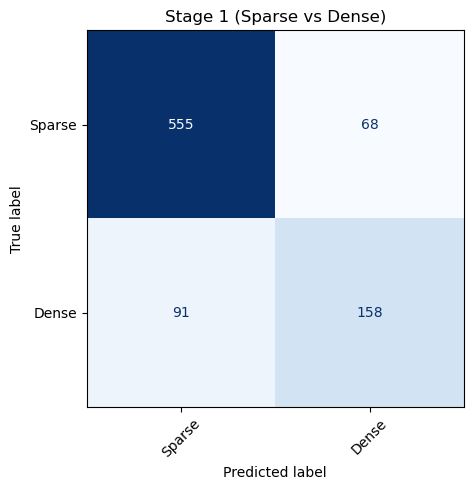

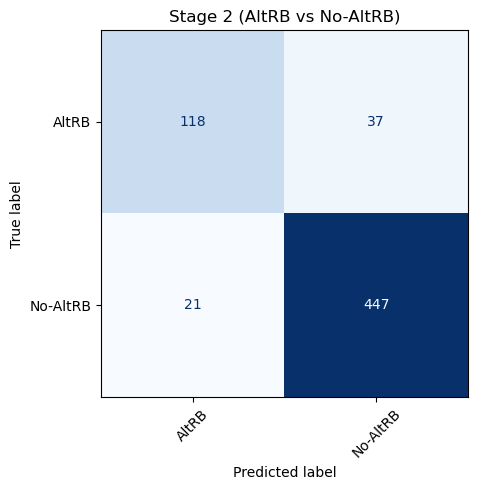

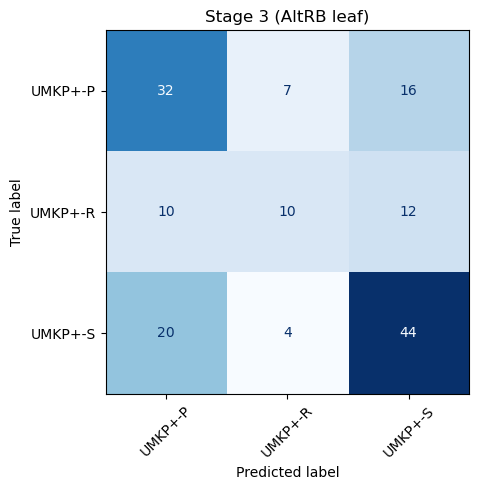

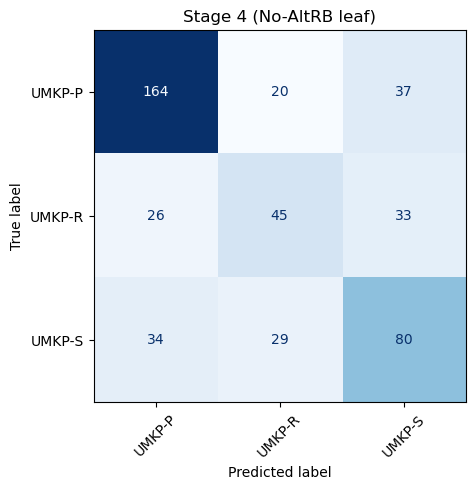

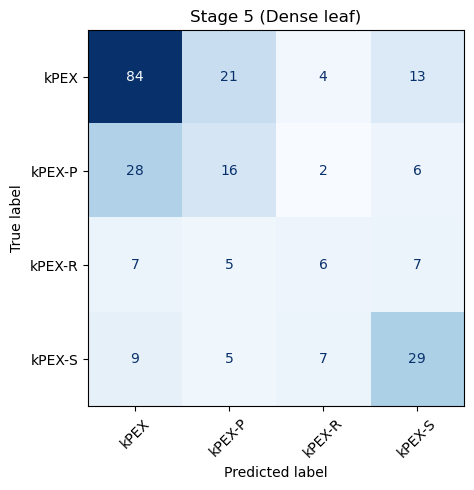

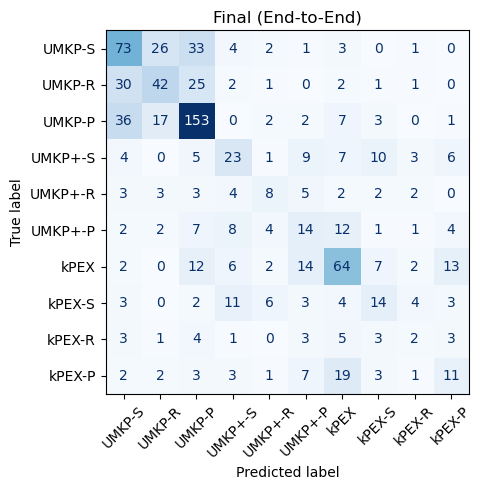


Stage-wise Summary Metrics

                         Stage  Samples  Accuracy  Avg Precision  Avg Recall  \
0    Stage 1 (Sparse vs Dense)      872  0.817661       0.779124    0.762694   
1  Stage 2 (AltRB vs No-AltRB)      623  0.906902       0.886237    0.858209   
2         Stage 3 (AltRB leaf)      155  0.554839       0.534477    0.513792   
3      Stage 4 (No-AltRB leaf)      468  0.617521       0.581400    0.578071   
4         Stage 5 (Dense leaf)      249  0.542169       0.459934    0.454054   
5           Final (End-to-End)      872  0.463303       0.365784    0.354555   

     Avg F1  
0  0.769984  
1  0.870898  
2  0.517646  
3  0.579233  
4  0.455085  
5  0.358600  


In [44]:
summary_df, per_class_reports = evaluate_hierarchical_stages(
    predictions_df.loc[X_test.index],
    hclf5_strat_y,
    X_test[feature_cols].values,
    algorithms
)


In [45]:
per_class_reports

{'Stage 1 (Sparse vs Dense)':               precision    recall  f1-score     support
 Sparse         0.859133  0.890851  0.874704  623.000000
 Dense          0.699115  0.634538  0.665263  249.000000
 accuracy       0.817661  0.817661  0.817661    0.817661
 macro avg      0.779124  0.762694  0.769984  872.000000
 weighted avg   0.813440  0.817661  0.814898  872.000000,
 'Stage 2 (AltRB vs No-AltRB)':               precision    recall  f1-score     support
 AltRB          0.848921  0.761290  0.802721  155.000000
 No-AltRB       0.923554  0.955128  0.939076  468.000000
 accuracy       0.906902  0.906902  0.906902    0.906902
 macro avg      0.886237  0.858209  0.870898  623.000000
 weighted avg   0.904985  0.906902  0.905151  623.000000,
 'Stage 3 (AltRB leaf)':               precision    recall  f1-score     support
 UMKP+-P        0.516129  0.581818  0.547009   55.000000
 UMKP+-R        0.476190  0.312500  0.377358   32.000000
 UMKP+-S        0.611111  0.647059  0.628571   68.000000
 a

In [46]:
save_stage_reports(
    report_obj=per_class_reports,
    file_name="hierarchical_per_class_report_test_set",
    output_dir='../outputs/XGB_results/hier5/strat_y',
    to_excel=True
)



Saved stage report to: ../outputs/XGB_results/hier5/strat_y\hierarchical_per_class_report_test_set.xlsx


In [47]:
save_stage_reports(
    report_obj=summary_df,
    file_name="hierarchical_summary_report_test_set",
    output_dir='../outputs/XGB_results/hier5/strat_y',
    to_excel=True
)


Saved stage report to: ../outputs/XGB_results/hier5/strat_y\hierarchical_summary_report_test_set.xlsx


#### Inference on Entire Dataset

In [48]:
classification_metrics, time_metrics, predictions_df, wrong_predictions_df = run_full_evaluation_hier5(
    cat_df=cat_df,
    clf=hclf5_strat_y,
    features=data_splits.feature_cols,
    algorithms=data_splits.algorithms,
    epsilon=1e-3,
    save_files=True,               # set False if you don’t want to write files
    output_dir='../outputs/XGB_results/hier5/strat_y',
    file_suffix= "inference_entire_data_without_holdout" # change exp number
)

write_metrics_to_excel_file(
    classification_metrics,
    time_metrics,
    "../outputs/XGB_results/hier5/model_performance_for_all_exp.xlsx",
    "Inference_entire_data_strat_y"
)


Predicting final outputs...
Adding hierarchical leaf probabilities...
Adding hierarchical stage probabilities...

Classification performance:
Accuracy (counting ties as correct): 84.62%

Precision by Algorithm:
  UMKP-S: 84.12% (737 predictions)
  UMKP-R: 85.38% (513 predictions)
  UMKP-P: 88.90% (1126 predictions)
  UMKP+-S: 84.88% (324 predictions)
  UMKP+-R: 82.78% (151 predictions)
  UMKP+-P: 77.41% (270 predictions)
  kPEX: 82.86% (636 predictions)
  kPEX-S: 83.74% (246 predictions)
  kPEX-R: 79.82% (109 predictions)
  kPEX-P: 81.15% (244 predictions)

Recall by Algorithm:
  UMKP-S: 86.59% (620/716 cases)
  UMKP-R: 84.23% (438/520 cases)
  UMKP-P: 90.67% (1001/1104 cases)
  UMKP+-S: 81.60% (275/337 cases)
  UMKP+-R: 79.11% (125/158 cases)
  UMKP+-P: 75.54% (210/278 cases)
  kPEX: 86.60% (530/612 cases)
  kPEX-S: 82.47% (207/251 cases)
  kPEX-R: 70.40% (88/125 cases)
  kPEX-P: 75.57% (198/262 cases)
Time Metrics:
  Total Predicted Time = 154483.17
  Total Optimal Time   = 111146.05

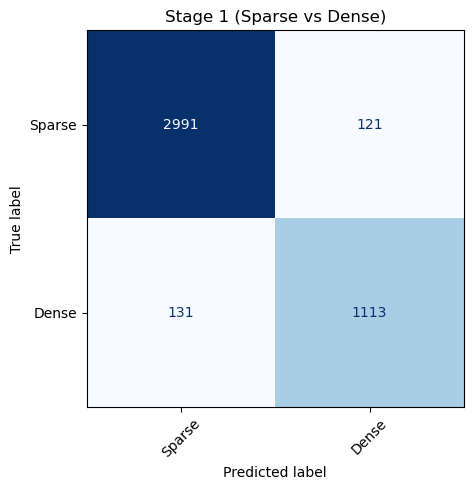

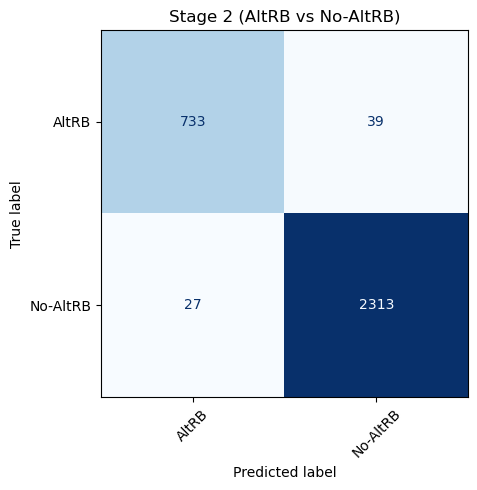

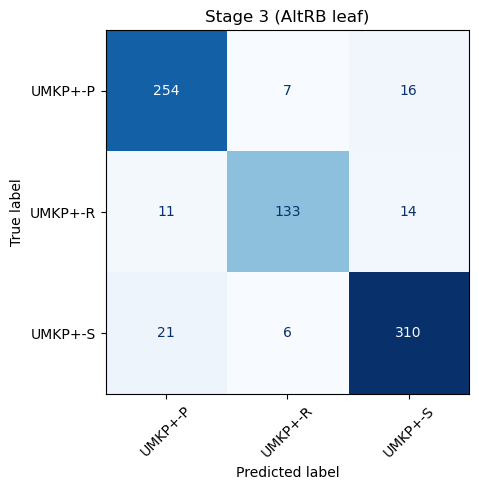

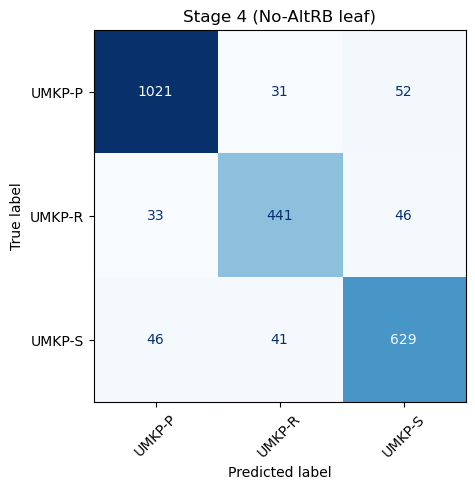

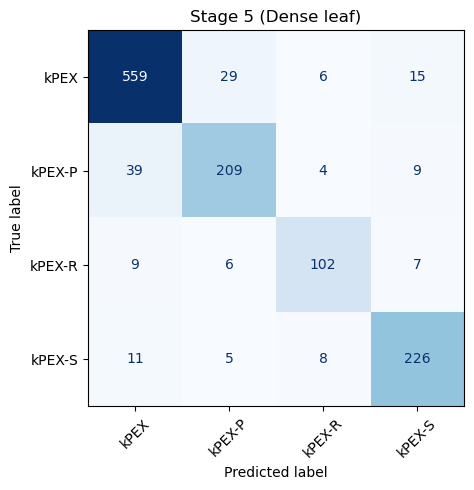

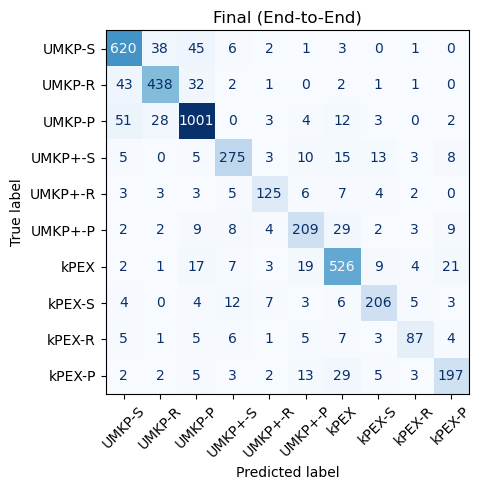


Stage-wise Summary Metrics

                         Stage  Samples  Accuracy  Avg Precision  Avg Recall  \
0    Stage 1 (Sparse vs Dense)     4356  0.942149       0.929992    0.927906   
1  Stage 2 (AltRB vs No-AltRB)     3112  0.978792       0.973946    0.968972   
2         Stage 3 (AltRB leaf)      772  0.902850       0.903612    0.892874   
3      Stage 4 (No-AltRB leaf)     2340  0.893590       0.884343    0.883796   
4         Stage 5 (Dense leaf)     1244  0.881029       0.868316    0.861311   
5           Final (End-to-End)     4356  0.845730       0.830468    0.812072   

     Avg F1  
0  0.928941  
1  0.971426  
2  0.897705  
3  0.884039  
4  0.864589  
5  0.820709  


In [50]:
X_full = predictions_df[feature_cols].values

summary_df, per_class_reports = evaluate_hierarchical_stages(
    predictions_df,
    hclf5_strat_y,
    X_full,
    algorithms
)


In [51]:
per_class_reports

{'Stage 1 (Sparse vs Dense)':               precision    recall  f1-score      support
 Sparse         0.958040  0.961118  0.959577  3112.000000
 Dense          0.901945  0.894695  0.898305  1244.000000
 accuracy       0.942149  0.942149  0.942149     0.942149
 macro avg      0.929992  0.927906  0.928941  4356.000000
 weighted avg   0.942020  0.942149  0.942078  4356.000000,
 'Stage 2 (AltRB vs No-AltRB)':               precision    recall  f1-score      support
 AltRB          0.964474  0.949482  0.956919   772.000000
 No-AltRB       0.983418  0.988462  0.985934  2340.000000
 accuracy       0.978792  0.978792  0.978792     0.978792
 macro avg      0.973946  0.968972  0.971426  3112.000000
 weighted avg   0.978719  0.978792  0.978736  3112.000000,
 'Stage 3 (AltRB leaf)':               precision    recall  f1-score    support
 UMKP+-P        0.888112  0.916968  0.902309  277.00000
 UMKP+-R        0.910959  0.841772  0.875000  158.00000
 UMKP+-S        0.911765  0.919881  0.915805  337.

In [52]:
save_stage_reports(
    report_obj=per_class_reports,
    file_name="hierarchical_per_class_report_entire_data",
    output_dir='../outputs/XGB_results/hier5/strat_y',
    to_excel=True
)



Saved stage report to: ../outputs/XGB_results/hier5/strat_y\hierarchical_per_class_report_entire_data.xlsx


In [53]:
save_stage_reports(
    report_obj=summary_df,
    file_name="hierarchical_summary_report_entire_data",
    output_dir='../outputs/XGB_results/hier5/strat_y',
    to_excel=True
)


Saved stage report to: ../outputs/XGB_results/hier5/strat_y\hierarchical_summary_report_entire_data.xlsx


### **Balanced train-test split based on Y and K**

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

def prepare_train_test_strat_Y_K_hier(cat_df,
                       weight_col='weight',
                       test_size=0.2,
                       random_state=42,
                       for_nn=False,
                       kcore_list=None,
                       tie_tolerance=0.00):

    if kcore_list:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize', 'kcore_list']
    elif for_nn:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize', 'fastest_time']
    else:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize']

    X = cat_df[feature_cols]

    y_algo = cat_df['y_algo']
    y_group = cat_df['y_group']
    y_sparse_subgroup = cat_df['y_sparse_subgroup']

    weight_group = cat_df['weight_group']
    weight_sparse = cat_df['weight_sparse_subgroup']
    weight_altRB = cat_df['weight_altRB']
    weight_noAltRB = cat_df['weight_noAltRB']
    weight_dense = cat_df['weight_dense']

    stratify_var = y_algo.astype(str) + "_k" + cat_df['k_value'].astype(str)

    X_train, X_test, \
    y_algo_train, y_algo_test = train_test_split(
        X, y_algo,
        test_size=test_size,
        random_state=random_state,
        stratify=stratify_var
    )

    idx_train = X_train.index
    idx_test = X_test.index

    return (
        X_train, X_test,
        y_algo_train, y_algo_test,

        y_group.loc[idx_train], y_group.loc[idx_test],
        y_sparse_subgroup.loc[idx_train], y_sparse_subgroup.loc[idx_test],

        weight_group.loc[idx_train], weight_group.loc[idx_test],
        weight_sparse.loc[idx_train], weight_sparse.loc[idx_test],
        weight_altRB.loc[idx_train], weight_altRB.loc[idx_test],
        weight_noAltRB.loc[idx_train], weight_noAltRB.loc[idx_test],
        weight_dense.loc[idx_train], weight_dense.loc[idx_test],
    )


In [ ]:
# from data_splits import prepare_train_test_strat_Y_K_hier

X_train, X_test, \
y_algo_train, y_algo_test, \
y_group_train, y_group_test, \
y_sparse_subgroup_train, y_sparse_subgroup_test, \
weight_group_train, weight_group_test, \
weight_sparse_train, weight_sparse_test, \
weight_altRB_train, weight_altRB_test, \
weight_noAltRB_train, weight_noAltRB_test, \
weight_dense_train, weight_dense_test = prepare_train_test_strat_Y_K_hier(
                                                                            cat_df,
                                                                            tie_tolerance = 0.0  # algorithms within tie_tolerance% of min treated as ties
                                                                        )

In [ ]:
hclf5_strat_y_K = HierarchicalClassifier5(
    group_clf=group_clf,
    sparse_subgroup_clf=sparse_subgroup_clf,
    altRB_clf=altRB_clf,
    noAltRB_clf=noAltRB_clf,
    dense_clf=dense_clf,
    tau_group=0.0,
    tau_sparse=0.0,
    tau_algo=0.0,
    fallback_label="SAFE_DEFAULT_ALGO"
)


In [ ]:
hclf5_strat_y_K.fit(
    X_train.values,                 # ensure numpy array
    y_group_train.values,
    y_sparse_subgroup_train.values,
    y_algo_train.values,

    weight_group=weight_group_train.values,
    weight_sparse=weight_sparse_train.values,
    weight_altRB=weight_altRB_train.values,
    weight_noAltRB=weight_noAltRB_train.values,
    weight_dense=weight_dense_train.values
)


In [ ]:
hclf5_strat_y_K.predict_proba(X_test.values)

array([[5.20212858e-03, 9.69067414e-03, 2.38333049e-02, ...,
        7.54950538e-02, 7.21868183e-02, 4.68587537e-02],
       [7.57933576e-03, 1.30929451e-02, 5.91860692e-03, ...,
        5.64928564e-03, 1.02331322e-02, 6.75098513e-03],
       [1.69075098e-03, 1.02477544e-01, 7.62771123e-01, ...,
        4.18293662e-04, 1.62356440e-04, 8.64360095e-04],
       ...,
       [5.29494872e-03, 9.16383359e-03, 1.73723690e-02, ...,
        6.50469629e-03, 1.54951791e-02, 5.59908323e-03],
       [2.05005725e-02, 1.50788781e-02, 4.46580835e-02, ...,
        5.93771485e-02, 6.44016286e-02, 9.01467090e-02],
       [4.01886083e-02, 1.66845586e-01, 6.27392363e-02, ...,
        5.66744700e-02, 6.18057142e-02, 2.32128625e-02]])

#### Inference on 20% Dataset

In [ ]:
classification_metrics, time_metrics, predictions_df, wrong_predictions_df = run_full_evaluation_hier5(
    cat_df=cat_df.loc[X_test.index],
    clf=hclf5_strat_y_K,
    features=data_splits.feature_cols,
    algorithms=data_splits.algorithms,
    epsilon=1e-3,
    save_files=True,               # set False if you don’t want to write files
    output_dir='../outputs/XGB_results/hier5/strat_y_K',
    file_suffix= "inference_test_data_without_holdout" # change exp number
)

write_metrics_to_excel_file(
    classification_metrics,
    time_metrics,
    "../outputs/XGB_results/hier5/model_performance_for_all_exp.xlsx",
    "Inference_test_data_strat_y_K"
)


Predicting final outputs...
Adding hierarchical leaf probabilities...
Adding hierarchical stage probabilities...

Classification performance:
Accuracy (counting ties as correct): 38.76%

Precision by Algorithm:
  UMKP-S: 37.00% (200 predictions)
  UMKP-R: 27.50% (80 predictions)
  UMKP-P: 54.55% (198 predictions)
  UMKP+-S: 32.61% (46 predictions)
  UMKP+-R: 19.35% (31 predictions)
  UMKP+-P: 18.52% (27 predictions)
  kPEX: 42.51% (207 predictions)
  kPEX-S: 26.32% (57 predictions)
  kPEX-R: 18.18% (11 predictions)
  kPEX-P: 20.00% (15 predictions)

Recall by Algorithm:
  UMKP-S: 51.75% (74/143 cases)
  UMKP-R: 20.95% (22/105 cases)
  UMKP-P: 48.65% (108/222 cases)
  UMKP+-S: 22.39% (15/67 cases)
  UMKP+-R: 18.18% (6/33 cases)
  UMKP+-P: 9.26% (5/54 cases)
  kPEX: 71.54% (88/123 cases)
  kPEX-S: 30.00% (15/50 cases)
  kPEX-R: 8.33% (2/24 cases)
  kPEX-P: 5.88% (3/51 cases)
Time Metrics:
  Total Predicted Time = 74081.34
  Total Optimal Time   = 21427.86
  Time Ratio (pred/opt)= 3.457
 

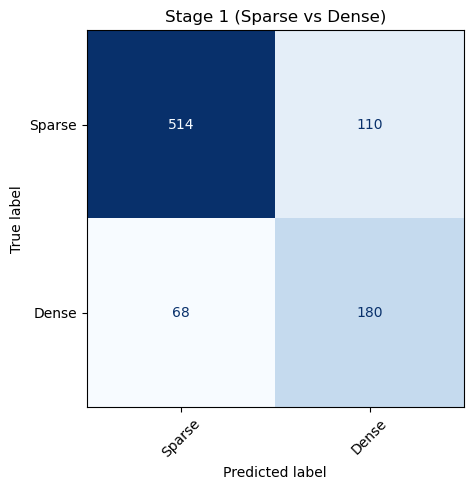

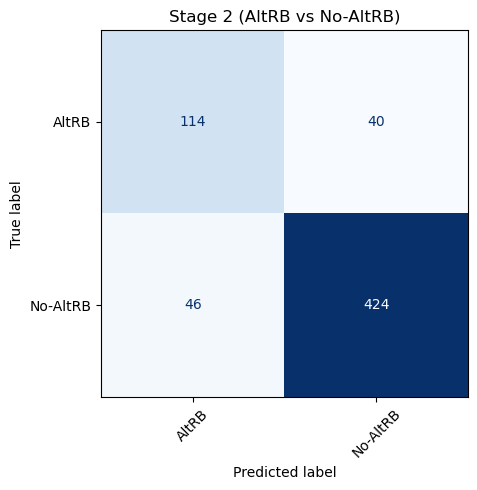

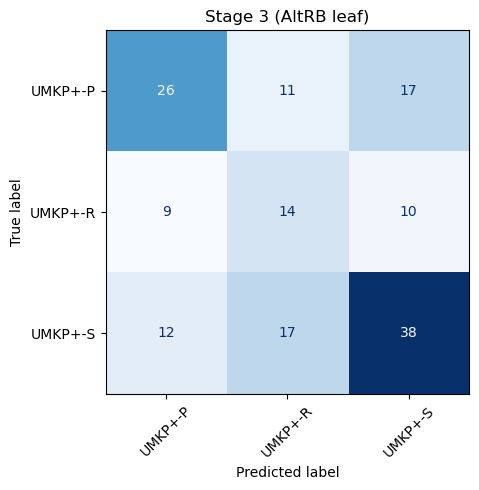

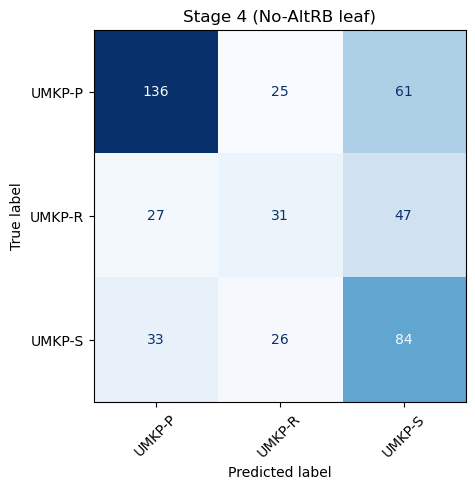

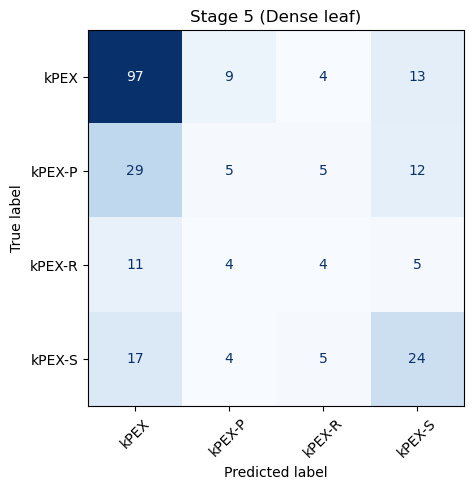

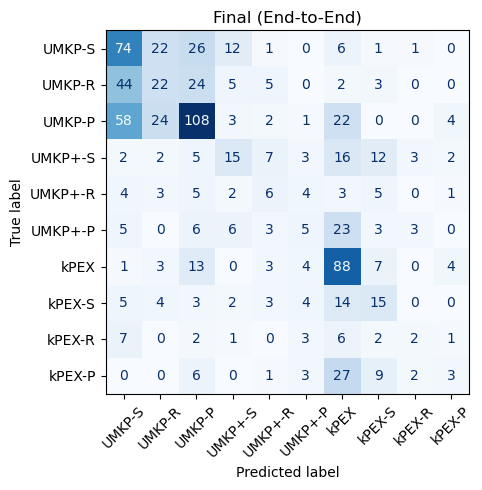


Stage-wise Summary Metrics

                         Stage  Samples  Accuracy  Avg Precision  Avg Recall  \
0    Stage 1 (Sparse vs Dense)      872  0.795872       0.751926    0.774762   
1  Stage 2 (AltRB vs No-AltRB)      624  0.862179       0.813147    0.821194   
2         Stage 3 (AltRB leaf)      154  0.506494       0.490380    0.490963   
3      Stage 4 (No-AltRB leaf)      470  0.534043       0.503142    0.498421   
4         Stage 5 (Dense leaf)      248  0.524194       0.380952    0.383331   
5           Final (End-to-End)      872  0.387615       0.296537    0.286939   

     Avg F1  
0  0.760775  
1  0.817019  
2  0.487981  
3  0.494587  
4  0.372340  
5  0.277896  


In [ ]:
summary_df, per_class_reports = evaluate_hierarchical_stages(
    predictions_df.loc[X_test.index],
    hclf5_strat_y_K,
    X_test[feature_cols].values,
    algorithms
)


In [ ]:
per_class_reports

{'Stage 1 (Sparse vs Dense)':               precision    recall  f1-score     support
 Sparse         0.883162  0.823718  0.852405  624.000000
 Dense          0.620690  0.725806  0.669145  248.000000
 accuracy       0.795872  0.795872  0.795872    0.795872
 macro avg      0.751926  0.774762  0.760775  872.000000
 weighted avg   0.808514  0.795872  0.800285  872.000000,
 'Stage 2 (AltRB vs No-AltRB)':               precision    recall  f1-score     support
 AltRB          0.712500  0.740260  0.726115  154.000000
 No-AltRB       0.913793  0.902128  0.907923  470.000000
 accuracy       0.862179  0.862179  0.862179    0.862179
 macro avg      0.813147  0.821194  0.817019  624.000000
 weighted avg   0.864115  0.862179  0.863054  624.000000,
 'Stage 3 (AltRB leaf)':               precision    recall  f1-score     support
 UMKP+-P        0.553191  0.481481  0.514851   54.000000
 UMKP+-R        0.333333  0.424242  0.373333   33.000000
 UMKP+-S        0.584615  0.567164  0.575758   67.000000
 a

In [ ]:
save_stage_reports(
    report_obj=per_class_reports,
    file_name="hierarchical_per_class_report_test_set",
    output_dir='../outputs/XGB_results/hier5/strat_y_K',
    to_excel=True
)



Saved stage report to: ../outputs/RF_results/hier5/strat_y_K\hierarchical_per_class_report_test_set.xlsx


In [ ]:
save_stage_reports(
    report_obj=summary_df,
    file_name="hierarchical_summary_report_test_set",
    output_dir='../outputs/XGB_results/hier5/strat_y_K',
    to_excel=True
)


Saved stage report to: ../outputs/RF_results/hier5/strat_y_K\hierarchical_summary_report_test_set.xlsx


#### Inference on Entire Dataset

In [ ]:
classification_metrics, time_metrics, predictions_df, wrong_predictions_df = run_full_evaluation_hier5(
    cat_df=cat_df,
    clf=hclf5_strat_y_K,
    features=data_splits.feature_cols,
    algorithms=data_splits.algorithms,
    epsilon=1e-3,
    save_files=True,               # set False if you don’t want to write files
    output_dir='../outputs/XGB_results/hier5/strat_y_K',
    file_suffix= "inference_entire_data_without_holdout" # change exp number
)

write_metrics_to_excel_file(
    classification_metrics,
    time_metrics,
    "../outputs/XGB_results/hier5/model_performance_for_all_exp.xlsx",
    "Inference_entire_data_strat_y"
)


Predicting final outputs...
Adding hierarchical leaf probabilities...
Adding hierarchical stage probabilities...

Classification performance:
Accuracy (counting ties as correct): 56.75%

Precision by Algorithm:
  UMKP-S: 47.19% (996 predictions)
  UMKP-R: 51.30% (384 predictions)
  UMKP-P: 67.30% (954 predictions)
  UMKP+-S: 67.98% (253 predictions)
  UMKP+-R: 55.10% (147 predictions)
  UMKP+-P: 70.00% (130 predictions)
  kPEX: 52.88% (955 predictions)
  kPEX-S: 52.05% (317 predictions)
  kPEX-R: 62.35% (85 predictions)
  kPEX-P: 71.11% (135 predictions)

Recall by Algorithm:
  UMKP-S: 65.64% (470/716 cases)
  UMKP-R: 37.88% (197/520 cases)
  UMKP-P: 58.15% (642/1104 cases)
  UMKP+-S: 51.34% (173/337 cases)
  UMKP+-R: 51.27% (81/158 cases)
  UMKP+-P: 33.09% (92/278 cases)
  kPEX: 82.68% (506/612 cases)
  kPEX-S: 65.74% (165/251 cases)
  kPEX-R: 43.20% (54/125 cases)
  kPEX-P: 37.02% (97/262 cases)
Time Metrics:
  Total Predicted Time = 220280.85
  Total Optimal Time   = 111146.05
  Tim

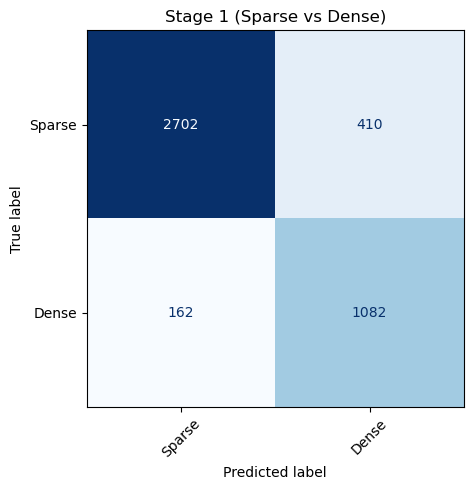

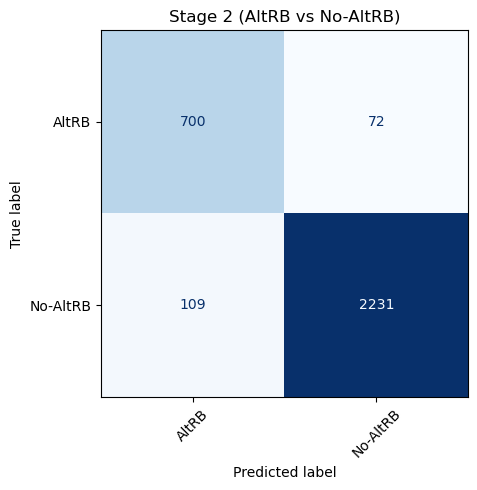

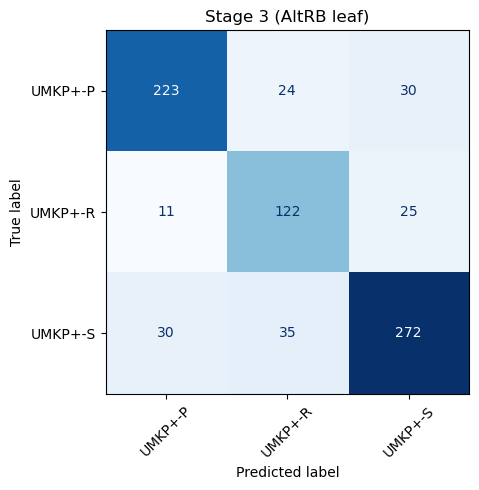

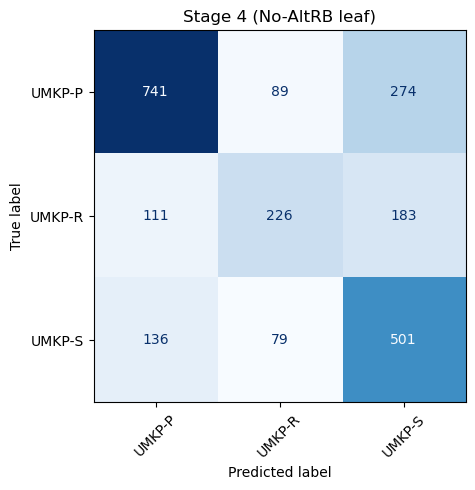

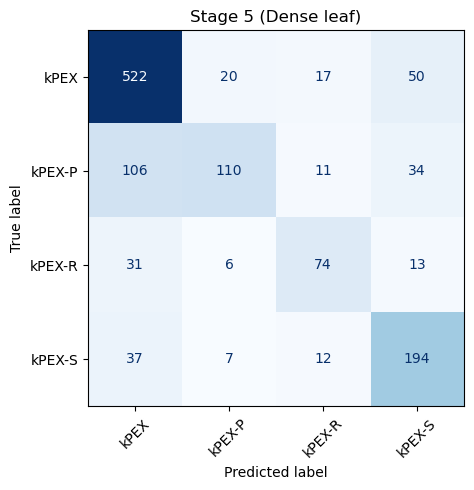

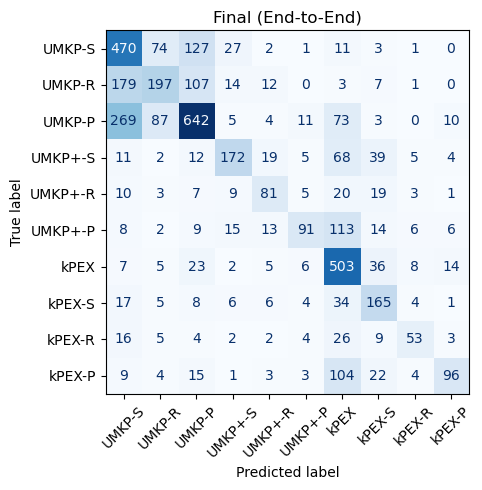


Stage-wise Summary Metrics

                         Stage  Samples  Accuracy  Avg Precision  Avg Recall  \
0    Stage 1 (Sparse vs Dense)     4356  0.868687       0.834318    0.869013   
1  Stage 2 (AltRB vs No-AltRB)     3112  0.941838       0.917001    0.930077   
2         Stage 3 (AltRB leaf)      772  0.799223       0.783511    0.794776   
3      Stage 4 (No-AltRB leaf)     2340  0.627350       0.615523    0.601844   
4         Stage 5 (Dense leaf)     1244  0.723473       0.708755    0.662843   
5           Final (End-to-End)     4356  0.567034       0.597057    0.524954   

     Avg F1  
0  0.847610  
1  0.923266  
2  0.787813  
3  0.600503  
4  0.670898  
5  0.538744  


In [ ]:
X_full = results_df[feature_cols].values

summary_df, per_class_reports = evaluate_hierarchical_stages(
    results_df,
    hclf5_strat_y_K,
    X_full,
    algorithms
)


In [ ]:
per_class_reports

{'Stage 1 (Sparse vs Dense)':               precision    recall  f1-score      support
 Sparse         0.943436  0.868252  0.904284  3112.000000
 Dense          0.725201  0.869775  0.790936  1244.000000
 accuracy       0.868687  0.868687  0.868687     0.868687
 macro avg      0.834318  0.869013  0.847610  4356.000000
 weighted avg   0.881112  0.868687  0.871913  4356.000000,
 'Stage 2 (AltRB vs No-AltRB)':               precision    recall  f1-score      support
 AltRB          0.865266  0.906736  0.885515   772.000000
 No-AltRB       0.968736  0.953419  0.961017  2340.000000
 accuracy       0.941838  0.941838  0.941838     0.941838
 macro avg      0.917001  0.930077  0.923266  3112.000000
 weighted avg   0.943068  0.941838  0.942287  3112.000000,
 'Stage 3 (AltRB leaf)':               precision    recall  f1-score     support
 UMKP+-P        0.844697  0.805054  0.824399  277.000000
 UMKP+-R        0.674033  0.772152  0.719764  158.000000
 UMKP+-S        0.831804  0.807122  0.819277  3

In [ ]:
save_stage_reports(
    report_obj=per_class_reports,
    file_name="hierarchical_per_class_report_entire_data",
    output_dir='../outputs/XGB_results/hier5/strat_y_K',
    to_excel=True
)



Saved stage report to: ../outputs/RF_results/hier5/strat_y_K\hierarchical_per_class_report_entire_data.xlsx


In [ ]:
save_stage_reports(
    report_obj=summary_df,
    file_name="hierarchical_summary_report_entire_data",
    output_dir='../outputs/XGB_results/hier5/strat_y_K',
    to_excel=True
)


Saved stage report to: ../outputs/RF_results/hier5/strat_y_K\hierarchical_summary_report_entire_data.xlsx
